# Modelagem da dinâmica do fósforo total na Lagoa do Taquaral por equações diferenciais
--------------------------------------------------------------------------------
**Trabalho Final de Equações Diferenciais** · Ilum Escola de Ciência (CNPEM) · 2026 <br>
**Autores:** Giovanna Avellar Machado, Bruna Henrique Fujihashi e Murillo Constantinov <br>
**Professor Orientador:** Prof. Dr. Vinícius Francisco Wasques

Este notebook contém a implementação computacional do trabalho. Ele:

1. calcula os parâmetros do modelo;
2. resolve a equação diferencial pelo método de Runge-Kutta de quarta ordem (RK4);
3. compara a solução numérica com a solução analítica e estima a ordem de convergência do método;
4. simula os cenários de recuperação da lagoa.

## Modelo

O modelo é o balanço de massa de Vollenweider, na forma de Toné e Lima Neto (2020), adaptado para incluir a liberação de fósforo pelo sedimento:

$$\frac{dP}{dt} = \frac{W_{ext}}{V} + \frac{r}{\bar z} - \left(\frac{1}{\tau} + k\right)P, \qquad P(0) = P_0.$$

Definindo $a = \dfrac{W_{ext}}{V} + \dfrac{r}{\bar z}$ e $\lambda = \dfrac{1}{\tau} + k$, a equação fica $\dfrac{dP}{dt} + \lambda P = a$, cuja solução analítica é

$$P(t) = \frac{a}{\lambda} + \left(P_0 - \frac{a}{\lambda}\right)e^{-\lambda t},$$

com ponto de equilíbrio estável $P^* = a/\lambda$.

**Como executar:** rode as células em ordem, de cima para baixo. Bibliotecas necessárias: NumPy, pandas e Matplotlib. As figuras são salvas em PNG e PDF na mesma pasta do notebook.

## 0. Bibliotecas

$ \ \ \ \ \ $ Para o desenvolvimento do trabalho as seguintes bibliotecas de linguagem Python (3.13.7) foram importadas: `numpy`, `pandas` e `matplotlib`. 

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.dpi": 120, "font.size": 13})

## 1. Parâmetros

Adota-se o **período chuvoso** como referência: $P_0$ e $T$ são as medidas de março de 2000 na Lagoa do Taquaral (Hernández Piedrahíta, 2002). A vazão da lagoa não foi medida; por isso, ela é estimada a partir do tempo de residência do Lago das Garças no período chuvoso (Henry et al., 2004), um reservatório urbano de características semelhantes. O coeficiente de decaimento $k$ é calculado pela Eq. (8) de Toné e Lima Neto (2020).

In [2]:
# ---------- Lagoa do Taquaral (Hernández Piedrahíta, 2002) ----------
V = 451_739.0          # volume (m³)
A = 155_771.86         # área (m²)
z = V / A              # profundidade média (m) = 2,90
P0 = 82.42             # fósforo total, março de 2000 (µg/L)
r = 5.0                # liberação de fósforo pelo sedimento (mg/m²·dia)
T = 23.6               # temperatura da água, março de 2000 (°C)

# ---------- Vazão: Lago das Garças (Henry et al., 2004) ----------
V_garcas = 88_156.0 * 2.14     # volume = área x profundidade média (m³)
tau_garcas = 43.0              # tempo de residência no período chuvoso (dias)
Q = V_garcas / tau_garcas      # vazão (m³/dia)
tau = V / Q                    # tempo de residência da Lagoa do Taquaral (dias)

# ---------- Coeficiente de decaimento (Toné e Lima Neto, 2020, Eq. 8) ----------
def k_tone(tau_dias, T):
    # a equação usa tau em anos e fornece k em 1/ano; o resultado é convertido para 1/dia
    tau_anos = tau_dias / 365.0
    return 0.769 * np.exp(0.025 * T) * 1.066 ** (T - 10) / np.sqrt(tau_anos) / 365.0

k = k_tone(tau, T)             # 1/dia
lam = 1 / tau + k              # taxa total de remoção (1/dia)
a_sed = r / z                  # entrada de fósforo pelo sedimento (µg/L·dia)

pd.DataFrame({
    "parâmetro": ["V (m³)", "A (m²)", "z̄ (m)", "P0 (µg/L)", "r (mg/m²·dia)", "T (°C)",
                  "Q (m³/dia)", "τ (dias)", "k (1/dia)", "λ (1/dia)", "r/z̄ (µg/L·dia)"],
    "valor": [V, A, z, P0, r, T, Q, tau, k, lam, a_sed],
}).round(4)

,parâmetro,valor
0,V (m³),451739.0000
1,A (m²),155771.8600
2,z̄ (m),2.9000
3,P0 (µg/L),82.4200
4,r (mg/m²·dia),5.0000
5,T (°C),23.6000
6,Q (m³/dia),4387.2986
7,τ (dias),102.9652
8,k (1/dia),0.0171
9,λ (1/dia),0.0268


## 2. A equação diferencial e a solução analítica

In [3]:
def f(t, P, a, lam):
    # lado direito da EDO: dP/dt = a - λP
    return a - lam * P

def P_exata(t, P0, a, lam):
    # solução analítica do PVI
    Pe = a / lam               # equilíbrio
    return Pe + (P0 - Pe) * np.exp(-lam * t)

## 3. Método de Runge-Kutta de quarta ordem

A cada passo, o método calcula quatro inclinações e usa uma média ponderada delas. As inclinações são chamadas de $\kappa_1, \dots, \kappa_4$ para não confundir com o coeficiente $k$ do modelo:

$$P_{n+1} = P_n + \frac{h}{6}\left(\kappa_1 + 2\kappa_2 + 2\kappa_3 + \kappa_4\right).$$

In [4]:
def rk4(f, P0, t_final, h, *args):
    n = int(round(t_final / h))
    t = np.linspace(0, n * h, n + 1)
    P = np.zeros(n + 1)
    P[0] = P0
    for i in range(n):
        kap1 = f(t[i],         P[i],                *args)   # inclinação no início do intervalo
        kap2 = f(t[i] + h / 2, P[i] + h * kap1 / 2, *args)   # no ponto médio, usando kap1
        kap3 = f(t[i] + h / 2, P[i] + h * kap2 / 2, *args)   # no ponto médio, usando kap2
        kap4 = f(t[i] + h,     P[i] + h * kap3,     *args)   # no fim do intervalo, usando kap3
        P[i + 1] = P[i] + h / 6 * (kap1 + 2 * kap2 + 2 * kap3 + kap4)
    return t, P

## 4. Verificação: RK4 × solução analítica

A verificação usa o caso em que apenas o sedimento libera fósforo ($a = r/\bar z$), por ter termo forçante não nulo. Os passos testados são potências de 2, de $h = 32$ dias (próximo do tempo característico $1/\lambda \approx 37$ dias) até $h = 1$ dia, que é o passo usado nos cenários. De um passo para o seguinte, $h$ cai pela metade; como o erro global do RK4 é proporcional a $h^4$, o erro deve cair cerca de $2^4 = 16$ vezes.

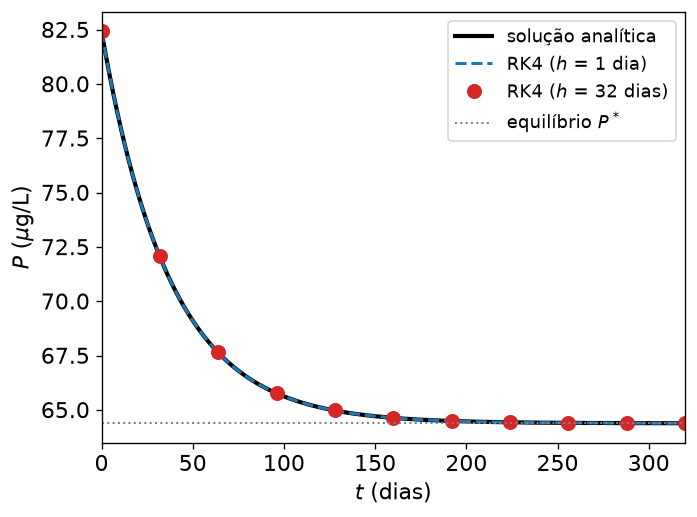

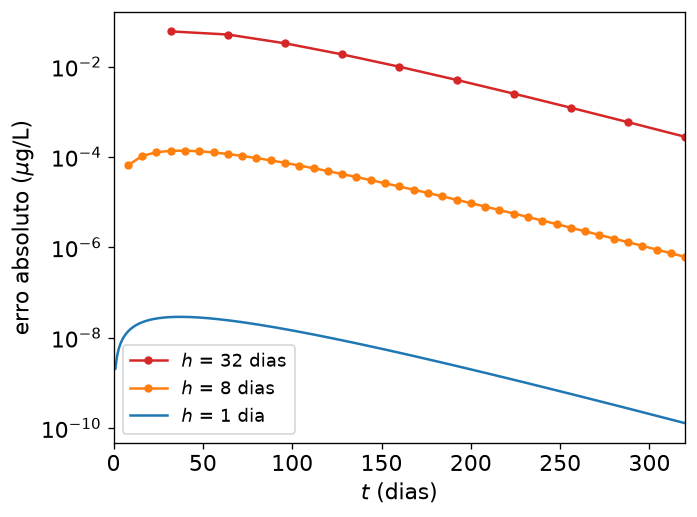

In [5]:
args = (a_sed, lam)
T_final = 320                  # múltiplo de todos os passos testados (dias)

# ---------- Figura: RK4 x solução analítica ----------
fig, ax = plt.subplots(figsize=(6, 4.5))
t_ex = np.linspace(0, T_final, 600)
ax.plot(t_ex, P_exata(t_ex, P0, *args), "k-", lw=2.5, label="solução analítica")
t1, P1 = rk4(f, P0, T_final, 1, *args)
ax.plot(t1, P1, "--", color="tab:blue", lw=1.8, label="RK4 ($h$ = 1 dia)")
t32, P32 = rk4(f, P0, T_final, 32, *args)
ax.plot(t32, P32, "o", color="tab:red", ms=8, label="RK4 ($h$ = 32 dias)")
ax.axhline(a_sed / lam, color="gray", ls=":", lw=1.2, label="equilíbrio $P^*$")
ax.set(xlabel="$t$ (dias)", ylabel="$P$ ($\\mu$g/L)", xlim=(0, T_final))
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig("fig_rk4_vs_analitica.png", dpi=300)
plt.savefig("fig_rk4_vs_analitica.pdf")
plt.show()

# ---------- Figura: erro do RK4 ao longo do tempo ----------
fig, ax = plt.subplots(figsize=(6, 4.5))
for h, cor in [(32, "tab:red"), (8, "tab:orange"), (1, "tab:blue")]:
    th, Ph = rk4(f, P0, T_final, h, *args)
    erro = np.abs(Ph - P_exata(th, P0, *args))
    ax.semilogy(th[1:], erro[1:], "o-" if h > 1 else "-", ms=4, color=cor,
                label=f"$h$ = {h} dia" + ("s" if h > 1 else ""))
ax.set(xlabel="$t$ (dias)", ylabel="erro absoluto ($\\mu$g/L)", xlim=(0, T_final))
ax.legend(fontsize=11)
plt.tight_layout()
plt.savefig("fig_rk4_erro.png", dpi=300)
plt.savefig("fig_rk4_erro.pdf")
plt.show()

### Tabela de erros e ordem de convergência

In [6]:
passos = [32, 16, 8, 4, 2, 1]
tab = []
for h in passos:
    th, Ph = rk4(f, P0, T_final, h, *args)
    Pex = P_exata(th, P0, *args)
    tab.append({"h (dias)": h,
                "erro máximo (µg/L)": np.max(np.abs(Ph - Pex)),
                "erro relativo máximo (%)": 100 * np.max(np.abs(Ph - Pex) / Pex)})
tab = pd.DataFrame(tab)
tab["razão (erro anterior / erro)"] = tab["erro máximo (µg/L)"].shift(1) / tab["erro máximo (µg/L)"]

# ordem de convergência: inclinação da reta log(erro) x log(h)
ordem = np.polyfit(np.log(tab["h (dias)"]), np.log(tab["erro máximo (µg/L)"]), 1)[0]
print(f"Ordem de convergência observada: {ordem:.2f} (teórica: 4)")
tab

Ordem de convergência observada: 4.18 (teórica: 4)


,h (dias),erro máximo (µg/L),erro relativo máximo (%),razão (erro anterior / erro)
0,32,6.063561e-02,8.417062e-02,NaN
1,16,2.638343e-03,3.717068e-03,22.982464
2,8,1.389746e-04,1.969523e-04,18.984356
3,4,7.955387e-06,1.125444e-05,17.469239
4,2,4.757092e-07,6.726412e-07,16.723214
5,1,2.907827e-08,4.112084e-08,16.359614


## 5. Cenários de recuperação

A carga externa $W_{ext}$ (esgoto e galerias pluviais) não foi medida. Por isso, o modelo é usado para prever o que ocorreria **a partir do momento em que todo o esgoto fosse interrompido** ($W_{ext} = 0$), partindo do fósforo medido em março de 2000:

- **Cenário A:** só o esgoto é cortado; o sedimento continua liberando fósforo, então $a = r/\bar z$.
- **Cenário B:** esgoto cortado e sedimento tratado (por exemplo, por dragagem), então $a = 0$ e $P(t) = P_0 e^{-\lambda t}$.

A meta é o limite de 30 µg/L da Resolução CONAMA 357/2005 para ambientes lênticos de classe 2. O tempo para atingi-lo é calculado pela fórmula analítica

$$t_{lim} = \frac{1}{\lambda}\ln\left(\frac{P_0 - P^*}{P_{lim} - P^*}\right),$$

válida quando $P^* < P_{lim} < P_0$, e conferido pela solução do RK4 com $h = 1$ dia.

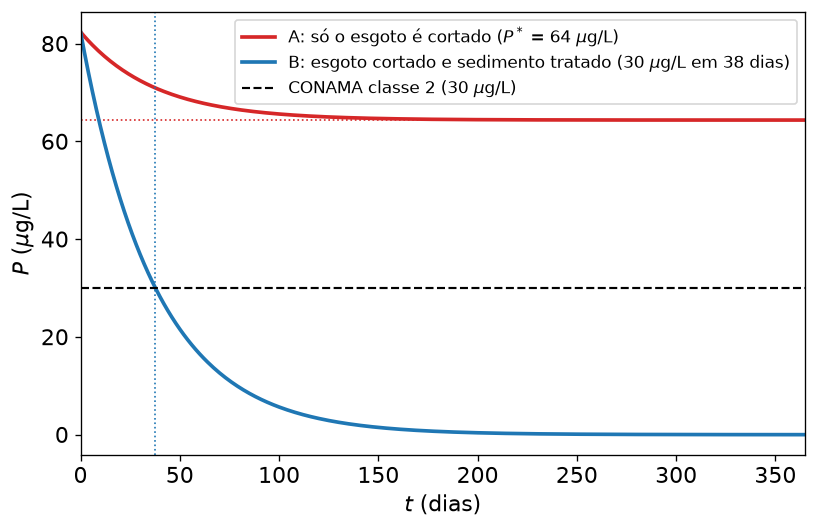

,cenário,a (µg/L·dia),P* (µg/L),"t até 30 µg/L, analítica (dias)","t até 30 µg/L, RK4 (dias)"
0,A,1.724,64.4,não atinge,não atinge
1,B,0.000,0.0,37.7,37.7


In [7]:
P_lim = 30.0       # µg/L
h = 1.0            # passo (dias)
T_sim = 365        # horizonte da simulação (dias)

def tempo_cruzamento(t, P, lim):
    # primeiro instante em que P <= lim, com interpolação linear entre dois passos
    abaixo = np.where(P <= lim)[0]
    if len(abaixo) == 0:
        return np.nan
    i = abaixo[0]
    return t[i - 1] + (P[i - 1] - lim) * (t[i] - t[i - 1]) / (P[i - 1] - P[i])

resultados = []
fig, ax = plt.subplots(figsize=(7, 4.6))
for cen, a_cen, cor, nome in [("A", a_sed, "tab:red", "A: só o esgoto é cortado"),
                              ("B", 0.0, "tab:blue", "B: esgoto cortado e sedimento tratado")]:
    t, P = rk4(f, P0, T_sim, h, a_cen, lam)
    Pe = a_cen / lam
    if Pe < P_lim < P0:
        t_an = np.log((P0 - Pe) / (P_lim - Pe)) / lam
        t_rk = tempo_cruzamento(t, P, P_lim)
        nome += f" (30 $\\mu$g/L em {t_an:.0f} dias)"
        ax.axvline(t_an, color=cor, ls=":", lw=1)
    else:
        t_an = t_rk = np.nan
        nome += f" ($P^*$ = {Pe:.0f} $\\mu$g/L)"
        ax.axhline(Pe, color=cor, ls=":", lw=1)
    ax.plot(t, P, color=cor, lw=2.2, label=nome)
    resultados.append({"cenário": cen,
                       "a (µg/L·dia)": round(a_cen, 3),
                       "P* (µg/L)": round(Pe, 1),
                       "t até 30 µg/L, analítica (dias)": "não atinge" if np.isnan(t_an) else round(t_an, 1),
                       "t até 30 µg/L, RK4 (dias)": "não atinge" if np.isnan(t_rk) else round(t_rk, 1)})
ax.axhline(P_lim, color="k", ls="--", lw=1.3, label="CONAMA classe 2 (30 $\\mu$g/L)")
ax.set(xlabel="$t$ (dias)", ylabel="$P$ ($\\mu$g/L)", xlim=(0, T_sim))
ax.legend(fontsize=10)
plt.tight_layout()
plt.savefig("fig_cenarios.png", dpi=300)
plt.savefig("fig_cenarios.pdf")
plt.show()

pd.DataFrame(resultados)

## Referências

- HENRY, R.; CARMO, C. F.; BICUDO, D. C. Trophic status of a Brazilian urban reservoir and prognosis about the recovery of water quality. *Acta Limnologica Brasiliensia*, v. 16, n. 3, p. 251-262, 2004.
- HERNÁNDEZ PIEDRAHÍTA, E. *Caracterização limnológica e estudo do processo de sedimentação e liberação de fósforo da Lagoa do Taquaral – Campinas (SP)*. Tese (Doutorado) – Escola de Engenharia de São Carlos, Universidade de São Paulo, 2002.
- TONÉ, A. J. A.; LIMA NETO, I. E. Modelagem simplificada do fósforo total em lagos e reservatórios brasileiros. *Revista DAE*, v. 68, n. 221, p. 142-156, 2020.
- VOLLENWEIDER, R. A. *Scientific fundamentals of the eutrophication of lakes and flowing waters*. Paris: OECD, 1968.
- BRASIL. Conselho Nacional do Meio Ambiente. Resolução CONAMA nº 357, de 17 de março de 2005.